## Dataset Features

The dataset contains **11 features** describing well identification, geological context, and petrophysical measurements, along with **one target variable (LITH)** used for lithology classification.

| Feature | Type | Description |
|---------|------|-------------|
| **WELL** | Categorical | Unique identifier for each well. It distinguishes measurements collected from different wells. |
| **DEPTH_MD** | Numerical | Measured depth (MD) at which each logging measurement was recorded, typically in meters. |
| **GROUP** | Categorical | Geological group representing a broad stratigraphic unit that contains one or more formations. |
| **FORMATION** | Categorical | Geological formation name indicating the specific rock layer at the recorded depth. |
| **CALI** | Numerical | Caliper log measuring the borehole diameter. It helps identify borehole enlargements (washouts) or irregularities that may affect other log measurements. |
| **RDEP** | Numerical | Deep resistivity log measuring the electrical resistivity of the formation away from the borehole. It is commonly used to distinguish hydrocarbon-bearing zones from water-bearing formations. |
| **RHOB** | Numerical | Bulk density log measuring the density of the surrounding rock. It is widely used for estimating porosity and identifying different rock types. |
| **GR** | Numerical | Gamma Ray log measuring the natural radioactivity of the formation. Higher values generally indicate shale-rich formations, while lower values suggest cleaner sandstone or carbonate rocks. |
| **NPHI** | Numerical | Neutron Porosity log estimating the hydrogen content of the formation, which is closely related to rock porosity and fluid content. |
| **PEF** | Numerical | Photoelectric Factor log measuring the photoelectric absorption of the formation. It is primarily used for lithology identification, especially when combined with density measurements. |
| **DTC** | Numerical | Compressional Sonic log measuring the travel time of acoustic waves through the formation. It provides information about rock elasticity, porosity, and mechanical properties. |
| **LITH** | Target | Lithology class representing the type of rock at each depth interval. This is the target variable for classification models. |

### Feature Categories

- **Well Information:** `WELL`
- **Depth Information:** `DEPTH_MD`
- **Geological Information:** `GROUP`, `FORMATION`
- **Borehole Condition:** `CALI`
- **Electrical Property:** `RDEP`
- **Density Measurement:** `RHOB`
- **Radioactivity Measurement:** `GR`
- **Porosity Measurement:** `NPHI`
- **Lithology Indicator:** `PEF`
- **Acoustic Measurement:** `DTC`
- **Target Variable:** `LITH`

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

In [26]:
df = pd.read_csv("../Data/Xeek_Well_15-9-15.csv")
df.head()

,WELL,DEPTH_MD,GROUP,FORMATION,CALI,RDEP,RHOB,GR,NPHI,PEF,DTC,LITH
0,15/9-15,485.256,NORDLAND GP.,NaN,NaN,1.735962,NaN,78.275825,NaN,NaN,161.947510,Shale
1,15/9-15,485.408,NORDLAND GP.,NaN,NaN,1.744778,NaN,79.214615,NaN,NaN,161.267715,Shale
2,15/9-15,485.560,NORDLAND GP.,NaN,NaN,1.752990,NaN,79.724106,NaN,NaN,160.644363,Shale
3,15/9-15,485.712,NORDLAND GP.,NaN,NaN,1.760675,NaN,81.042778,NaN,NaN,160.212601,Shale
4,15/9-15,485.864,NORDLAND GP.,NaN,NaN,1.767360,NaN,80.785133,NaN,NaN,160.315948,Shale


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17717 entries, 0 to 17716
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   WELL       17717 non-null  str    
 1   DEPTH_MD   17717 non-null  float64
 2   GROUP      17717 non-null  str    
 3   FORMATION  15093 non-null  str    
 4   CALI       17635 non-null  float64
 5   RDEP       17717 non-null  float64
 6   RHOB       17521 non-null  float64
 7   GR         17717 non-null  float64
 8   NPHI       13346 non-null  float64
 9   PEF        17662 non-null  float64
 10  DTC        17708 non-null  float64
 11  LITH       17717 non-null  str    
dtypes: float64(8), str(4)
memory usage: 1.6 MB


# Handling Missing Values

Missing values were handled as part of the data preprocessing step before feeding the data into the anomaly detection model to ensure clean and reliable input.

In [28]:

df = df.dropna()

In [29]:
df.info()

<class 'pandas.DataFrame'>
Index: 13290 entries, 4371 to 17707
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   WELL       13290 non-null  str    
 1   DEPTH_MD   13290 non-null  float64
 2   GROUP      13290 non-null  str    
 3   FORMATION  13290 non-null  str    
 4   CALI       13290 non-null  float64
 5   RDEP       13290 non-null  float64
 6   RHOB       13290 non-null  float64
 7   GR         13290 non-null  float64
 8   NPHI       13290 non-null  float64
 9   PEF        13290 non-null  float64
 10  DTC        13290 non-null  float64
 11  LITH       13290 non-null  str    
dtypes: float64(8), str(4)
memory usage: 1.3 MB


### Building an Isolation Forest Model Using Two Features: `NPHI` and `RHOB`

For this model, we use two well log features: **NPHI** and **RHOB**.

* **NPHI (Neutron Porosity):**
  NPHI measures the **neutron porosity** of the rock, which is an estimate of the amount of pore space within the formation. Higher NPHI values generally indicate higher porosity, meaning the rock has more empty spaces that can potentially contain fluids such as **oil, gas, or water**. Because porosity is a key property of reservoir rocks, NPHI is one of the most important measurements in well log analysis.

* **RHOB (Bulk Density):**
  RHOB measures the **bulk density** of the rock, including both the solid rock matrix and the fluids occupying the pore spaces. Lower bulk density values often correspond to higher porosity, while higher density values typically indicate more compact and less porous formations. RHOB is commonly analyzed together with NPHI to better understand the rock's physical properties and identify potential hydrocarbon-bearing zones.

Using these two features together allows the Isolation Forest model to detect observations with unusual combinations of porosity and bulk density, which may represent anomalies, measurement errors, or geologically distinct formations.

## Isolation Forest Algorithm

Isolation Forest is an unsupervised machine learning algorithm used for anomaly detection. It identifies unusual data points by isolating them from the rest of the observations.

The algorithm works by randomly selecting features and splitting the data to create multiple decision trees (isolation trees). Anomalies are easier to isolate because they are different from normal data points, requiring fewer splits to separate them. Normal observations usually require longer paths to be isolated.

The final anomaly score is calculated based on the average path length across all trees. Data points with shorter paths are considered more likely to be anomalies.

In this project, Isolation Forest is used to detect abnormal patterns in well log measurements that may represent unusual geological conditions or data quality issues.

## Mathematical Concept Behind Isolation Forest Anomaly Detection

In Isolation Forest, the decision of whether a data point is an anomaly is based on how easily it can be isolated from the rest of the data.

For a given data point, the algorithm calculates the **average path length** \(E(h(x))\) across multiple isolation trees, where:

- \(h(x)\) = path length required to isolate data point \(x\) in a tree
- \(E(h(x))\) = average path length across all trees

The anomaly score is calculated as:

\[
s(x,n) = 2^{-\frac{E(h(x))}{c(n)}}
\]

Where:

- \(s(x,n)\) = anomaly score of data point \(x\)
- \(n\) = number of samples in the dataset
- \(c(n)\) = average path length of an unsuccessful search in a binary tree, calculated as:

\[
c(n)=2H(n-1)-\frac{2(n-1)}{n}
\]

where \(H(n-1)\) is the harmonic number:

\[
H(n-1)=\ln(n-1)+0.5772156649
\]

### Interpretation of the Score

- **Score close to 1:** The point is easily isolated → likely an anomaly.
- **Score around 0.5:** The point has average behavior.
- **Score below 0.5:** The point is likely a normal observation.

The intuition is that anomalies are rare and different from the majority of data, so they require fewer random splits to isolate, resulting in shorter path lengths and higher anomaly scores.

In [30]:
# 2 Features as innput data
anomaly_inputs = ["NPHI", "RHOB"]

In [31]:
model_if = IsolationForest(contamination=0.1, random_state=42)
# tells. the model to look for 10 % of the entire data as an outlier
model_if.fit(df[anomaly_inputs])


,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [32]:
df["anomaly_scores"] = model_if.decision_function(df[anomaly_inputs]) 

## Isolation Forest Output Functions

After fitting the Isolation Forest model, the three main functions provide different levels of anomaly detection information:

- **`score_samples()`**: Returns the raw anomaly score based on how easily a point is isolated. Lower scores indicate points that are more likely to be anomalies.

- **`decision_function()`**: Converts the raw score into a value relative to the model threshold. Negative values indicate anomalies, while positive values indicate normal points.

- **`predict()`**: Gives the final classification decision:
  - `-1` → Anomaly
  - `1` → Normal

**Flow:**

`score_samples()` → raw isolation score  
`decision_function()` → score compared to threshold  
`predict()` → final anomaly label

In [33]:
df["anomaly"] = model_if.predict(df[anomaly_inputs]) 

In [34]:
df.loc[:, ['NPHI', 'RHOB', 'anomaly_scores', 'anomaly']]

,NPHI,RHOB,anomaly_scores,anomaly
4371,0.541850,2.063168,0.094522,1
4372,0.545401,2.051136,0.095207,1
4373,0.548953,2.041540,0.099837,1
4374,0.549356,2.035698,0.105620,1
4375,0.543351,2.029099,0.117897,1
...,...,...,...,...
17703,0.257656,2.391858,0.108037,1
17704,0.264047,2.408428,0.088239,1
17705,0.269605,2.432385,0.075509,1
17706,0.270624,2.452091,0.058709,1


# Communicating results

<Axes: xlabel='NPHI', ylabel='RHOB'>

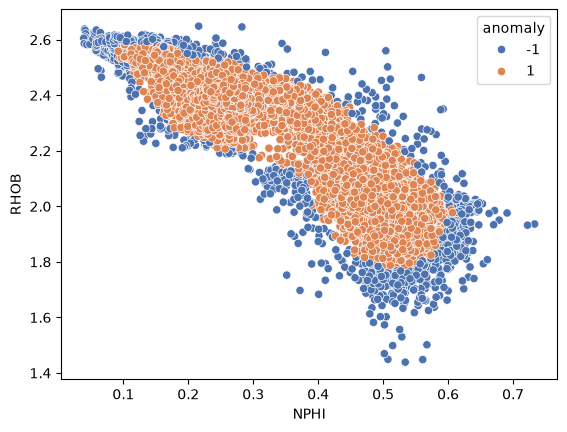

In [35]:

sns.scatterplot(data=df, x="NPHI", y="RHOB", hue="anomaly", palette="deep")

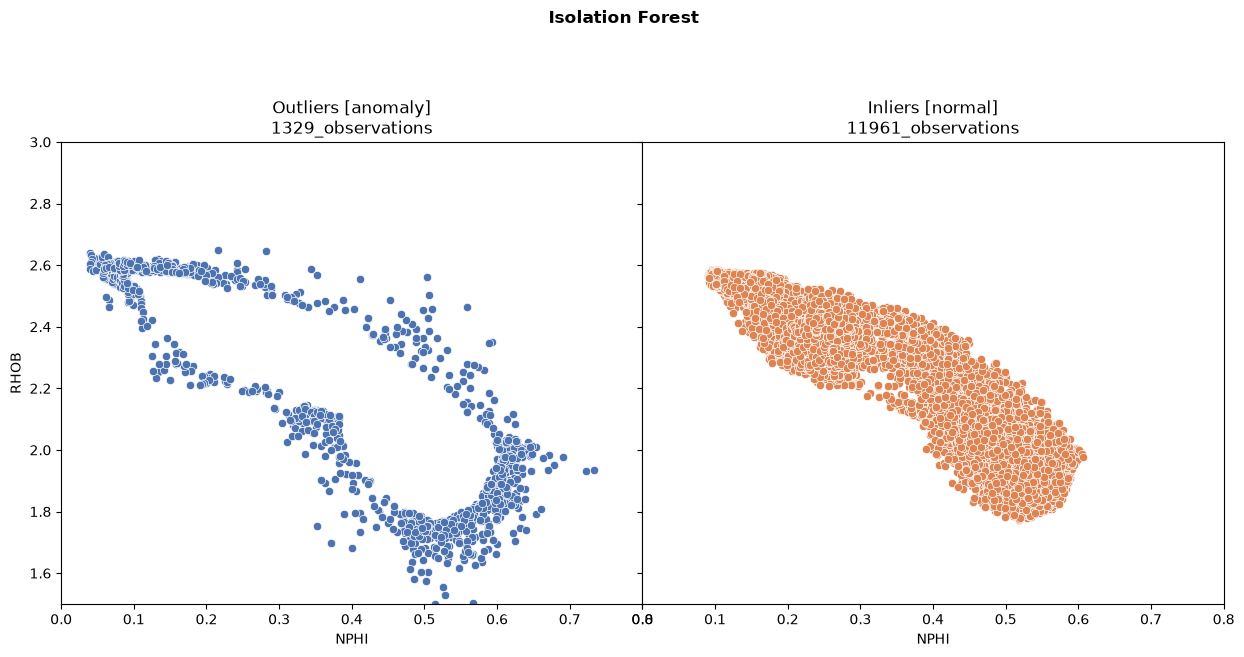

In [36]:
# Seperate the two categories
palette = sns.color_palette("deep")
fig,axes = plt.subplots(1,2,figsize=(15,6), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0, hspace=0)
sns.scatterplot(data=df[df["anomaly"]==-1], x="NPHI", y="RHOB", color=palette[0],ax=axes[0])
sns.scatterplot(data=df[df["anomaly"]==1], x="NPHI", y="RHOB",color=palette[1], ax=axes[1])
axes[0].set_title(f"Outliers [anomaly]\n{len(df[df["anomaly"]==-1])}_observations")
axes[1].set_title(f"Inliers [normal]\n{len(df[df["anomaly"]==1])}_observations")
fig.suptitle("Isolation Forest", fontweight="bold", y=1.10)
axes[0].set_xlim([0,0.8])
axes[0].set_ylim([1.5,3])
axes[1].set_xlim([0,0.8])
axes[1].set_ylim([1.5,3])
plt.savefig("../Figures/IF_two_features.png", dpi=150)

# we use palette only when we use hue and a contast applier

## Isolation Forest: Multiple Features

In [37]:
anomaly_inputs=["NPHI", "RHOB", "GR", "CALI", "PEF", "DTC"]
model_if = IsolationForest(contamination=0.1, random_state=42)
model_if.fit(df[anomaly_inputs])
df["anomaly_scores"] = model_if.decision_function(df[anomaly_inputs])
df["anomaly"] = model_if.predict(df[anomaly_inputs])

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/seaborn/axisgrid.py:1513: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  func(x=vector, **plot_kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/seaborn/axisgrid.py:1513: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  func(x=vector, **plot_kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/seaborn/axisgrid.py:1513: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  func(x=vector, **plot_kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/seaborn/axisgrid.py:1513: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  func(x=vector, **plot_kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/si

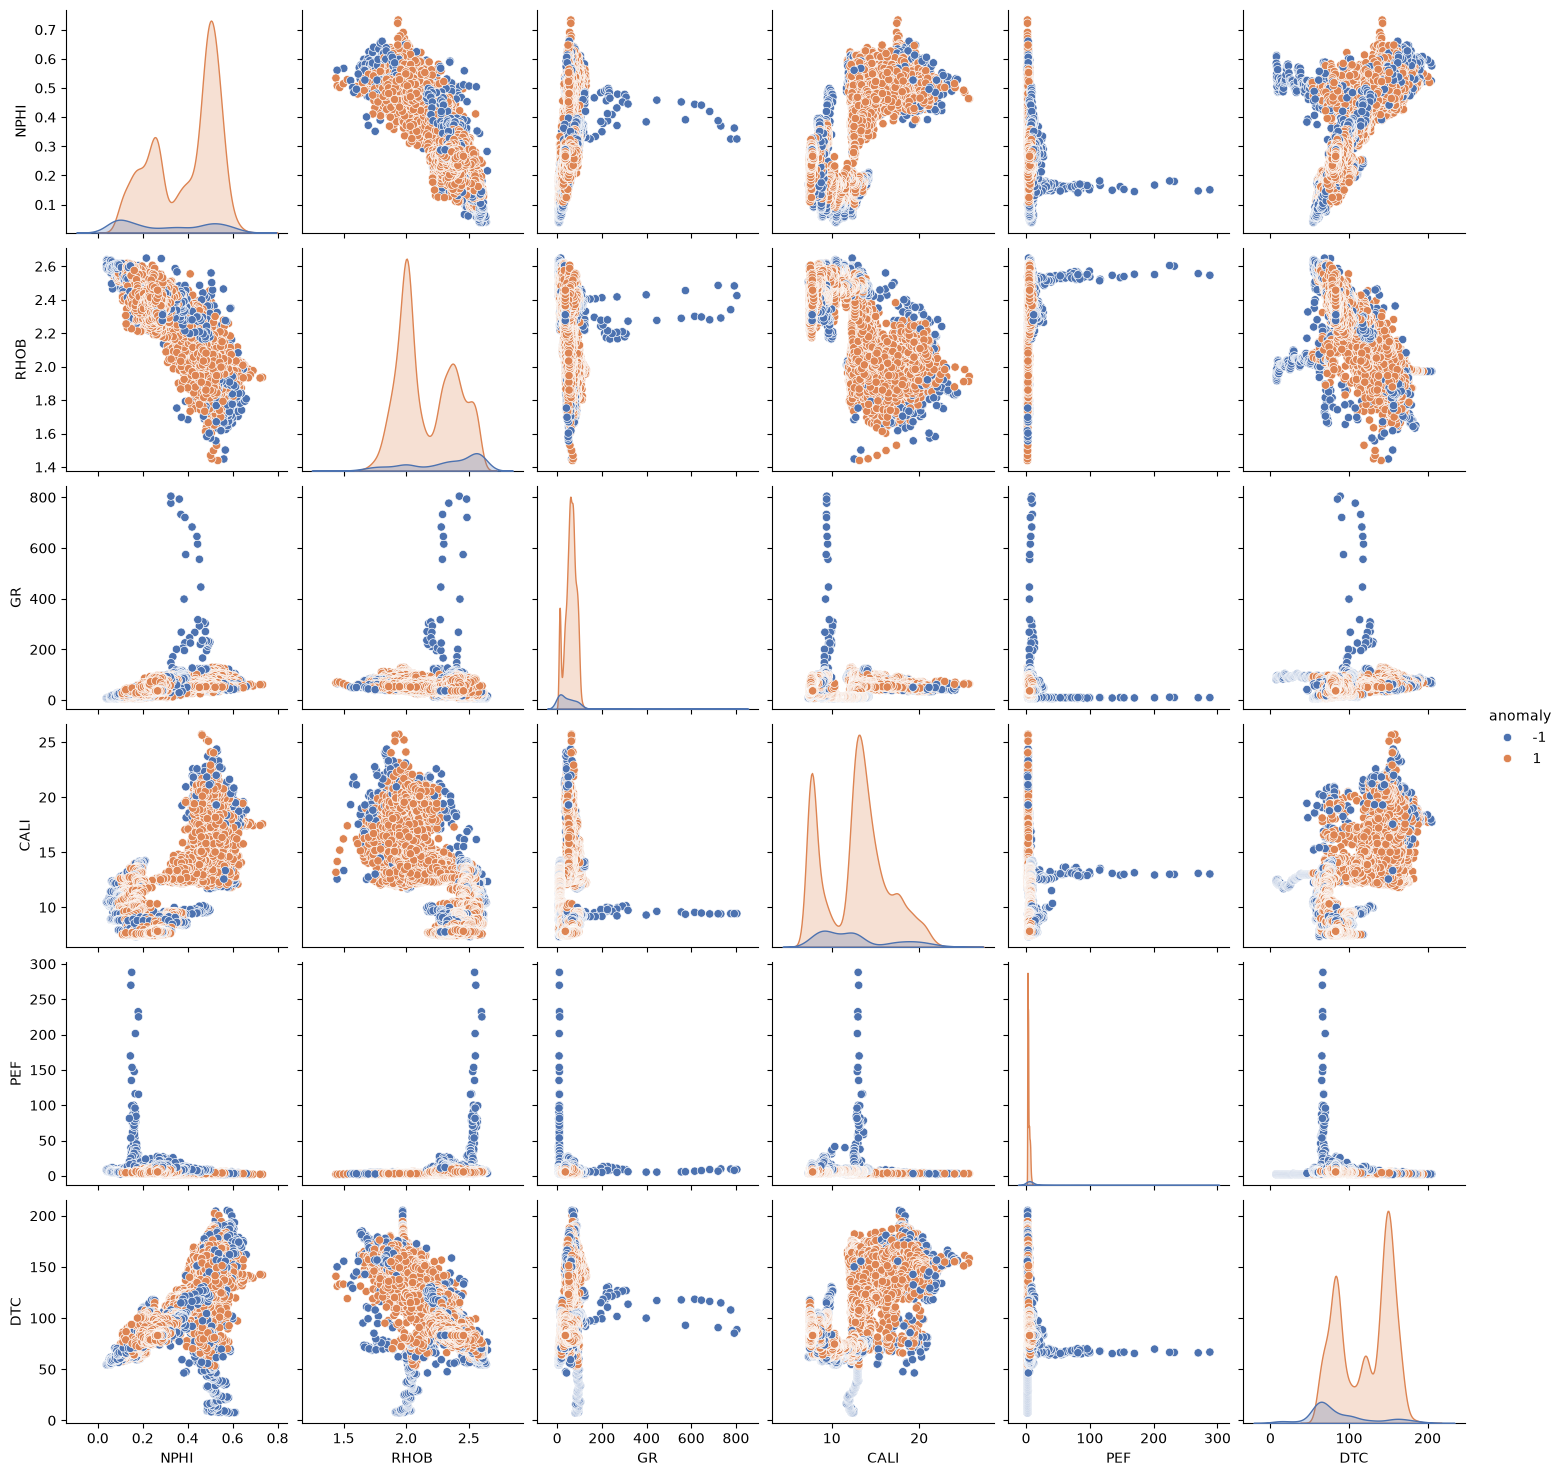

In [38]:
palette = sns.color_palette("deep")
# plotting the multidimensin plot
sns.pairplot(df, vars=anomaly_inputs, hue="anomaly", palette=palette);